# Inferência Bayesiana: O Problema da Moeda (Modelo Beta-Binomial)

Este notebook apresenta o fluxo completo de uma **análise estatística bayesiana** aplicado ao problema clássico de estimar o viés ($\theta$) de uma moeda a partir de lançamentos observados.

### Contexto Estatístico: Teorema de Bayes
Na inferência bayesiana, tratamos o parâmetro desconhecido $\theta \in [0, 1]$ (a probabilidade de sair "cara") como uma **variável aleatória** e atualizamos nossa incerteza sobre ele à medida que observamos os dados $y$, utilizando o **Teorema de Bayes**:

$$P(\theta \mid y) = \frac{P(y \mid \theta) \, P(\theta)}{P(y)}$$

* **$P(\theta)$ — Distribuição *a priori* (*Prior*):** Representa o conhecimento ou incerteza inicial sobre $\theta$ antes de observar os dados.
* **$P(y \mid \theta)$ — Verossimilhança (*Likelihood*):** Mede a plausibilidade dos dados observados $y$ para cada valor possível de $\theta$.
* **$P(\theta \mid y)$ — Distribuição *a posteriori* (*Posterior*):** Combina a *prior* com a verossimilhança, fornecendo a distribuição de probabilidade atualizada de $\theta$ após observar os dados.
* **$P(y) = \int P(y \mid \theta) P(\theta) d\theta$ — Evidência Marginal:** Constante normalizadora que garante que a *posterior* integre $1$.

---

## 1. Importação das Bibliotecas
Carregamos o ecossistema moderno de programação probabilística em Python:
* **`pymc` (`pm`):** Biblioteca de programação probabilística para especificação de modelos bayesianos e amostragem via MCMC (*Markov Chain Monte Carlo*).
* **`numpy` (`np`):** Computação numérica e manipulação de arrays.
* **`preliz` (`pz`):** Ferramenta voltada à elicitação e exploração de distribuições de probabilidade *a priori*.
* **`arviz` (`az`) e `arviz_plots.visuals` (`viz`):** Análise exploratória de modelos bayesianos, diagnósticos de convergência MCMC e visualização das distribuições *a posteriori*.

In [1]:
import pymc as pm
import numpy as np
import preliz as pz
import arviz as az
import arviz_plots.visuals as viz

## 2. Configuração Global de Estatísticas no ArviZ (`rcParams`)
No ArviZ `1.x`, definimos globalmente as convenções estatísticas clássicas da literatura bayesiana (como em *Bayesian Analysis with Python* e *Doing Bayesian Data Analysis* de John Kruschke):

1. **`stats.ci_kind = 'hdi'` (*Highest Density Interval*):** Em vez do intervalo de caudas iguais (*ETI*), utilizamos o **HDI** (Intervalo de Maior Densidade). Por definição, todos os pontos dentro do HDI possuem densidade de probabilidade maior do que qualquer ponto fora dele, resultando no **menor intervalo possível** para uma dada massa de probabilidade — propriedade essencial quando a distribuição *a posteriori* é assimétrica.
2. **`stats.ci_prob = 0.94` (94% de probabilidade):** Define que os intervalos de credibilidade conterão $94\%$ da massa de probabilidade *a posteriori*.
3. **`stats.point_estimate = 'mean'`:** Utiliza a **média *a posteriori*** ($\mathbb{E}[\theta \mid y]$) como estimativa pontual resumo (que minimiza a perda quadrática esperada).

In [2]:
az.rcParams['stats.ci_kind'] = 'hdi'
az.rcParams['stats.ci_prob'] = 0.94
az.rcParams['stats.point_estimate'] = 'mean'

## 3. Simulação do Processo Gerador de Dados
Definimos uma semente pseudoaleatória (`seed(123)`) para garantir total **reprodutibilidade** dos experimentos estocásticos.

In [3]:
np.random.seed(123)

### Geração da Amostra Sintética
Simulamos um experimento controlado onde conhecemos o verdadeiro parâmetro da população ($\theta_{\text{real}} = 0.35$, isto é, uma moeda enviesada que resulta em "cara" $35\%$ das vezes):
* **`trials = 4`:** Realizamos apenas $N = 4$ lançamentos independentes (amostra pequena, cenário onde a abordagem bayesiana se destaca por quantificar a incerteza exata).
* **`pz.Binomial(n=1, p=theta_real).rvs(trials)`:** Cada lançamento individual de uma moeda é um ensaio de **Bernoulli**, que equivale matematicamente a uma distribuição $\text{Binomial}(n=1, p=\theta_{\text{real}})$.

In [4]:
trials = 4
theta_real = 0.35
data = pz.Binomial(n=1, p=theta_real).rvs(trials, random_state=123)

### Inspeção dos Dados Observados
O vetor `data` armazena os resultados dos $4$ lançamentos ($1 = \text{cara/sucesso}$, $0 = \text{coroa/fracasso}$).
* **Resultado observado:** `array([1, 0, 0, 0])`, ou seja, $k = 1$ sucesso em $N = 4$ tentativas.
* **Contexto estatístico:** Se usássemos apenas a estimativa de Máxima Verossimilhança frequentista ($\hat{\theta}_{\text{MLE}} = \frac{k}{N}$), obteríamos $\hat{\theta}_{\text{MLE}} = \frac{1}{4} = 0.25$, sem capturar diretamente toda a assimetria da incerteza causada pelo tamanho reduzido da amostra.

In [5]:
data

array([1, 0, 0, 0])

## 4. Especificação do Modelo Bayesiano e Amostragem MCMC
Construímos o modelo probabilístico `our_first_model` utilizando a família conjugada **Beta-Bernoulli**:

1. **Distribuição *a priori*:**
   $$\theta \sim \text{Beta}(\alpha = 1, \beta = 1)$$
   A distribuição $\text{Beta}(1, 1)$ é equivalente a uma distribuição $\text{Uniforme}(0, 1)$. Ela representa uma *prior* **não-informativa** (equiprovável): antes de ver os lançamentos, consideramos qualquer valor de $\theta$ entre $0$ e $1$ igualmente plausível.
2. **Verossimilhança (*Likelihood*):**
   $$y_i \mid \theta \stackrel{\text{i.i.d.}}{\sim} \text{Bernoulli}(p = \theta), \quad i = 1, \dots, 4$$
3. **Amostragem MCMC via `nutpie` (`pm.sample`):**
   Embora este modelo possua solução analítica fechada pela conjugação Beta-Binomial:
   $$\theta \mid y \sim \text{Beta}(\alpha + k, \, \beta + N - k) = \text{Beta}(1 + 1, \, 1 + 3) = \text{Beta}(2, 4)$$
   utilizamos o amostrador Hamiltoniano **NUTS** (*No-U-Turn Sampler*) compilado via `nutpie` para gerar $4$ cadeias de $1000$ amostras ($4000$ amostras *a posteriori* no total).
4. **Amostragem *a priori* (`pm.sample_prior_predictive`):**
   Adicionamos $1000$ amostras da distribuição *a priori* ao objeto `idata` (`DataTree`) para possibilitar comparações futuras entre *prior* e *posterior* (como o Fator de Bayes).

In [6]:
with pm.Model() as our_first_model:
    theta = pm.Beta('θ', alpha=1., beta=1.)
    y = pm.Bernoulli('y', p=theta, observed=data)
    idata = pm.sample(1000, nuts_sampler='nutpie')

    idata.update(pm.sample_prior_predictive(1000)) # Como theta e uma distribuição Beta(1,1), então ela é identica a uma ditribuição Uniform(0, 1)


NUTS[nutpie]: [θ]


Output()

Sampling: [y, θ]


## 5. Representação Gráfica do Modelo (DAG / Diagrama no Estilo de Kruschke)
A função `pm.model_to_graphviz(our_first_model)` gera o **Grafo Acíclico Direcionado (DAG)** com notação de placas (*plate notation*):
* **Elipse clara ($\theta \sim \text{Beta}$):** Variável latente (parâmetro não observado que desejamos estimar).
* **Elipse sombreada em cinza ($y \sim \text{Bernoulli}$):** Variável observada (dados fixados pelo argumento `observed=data`).
* **Seta direcionada ($\theta \to y$):** Indica a dependência generativa e condicional de $y$ em relação a $\theta$.
* **Retângulo envolvente com número `4` (*Plate*):** Indica que a variável $y$ se repete para $N = 4$ observações independentes.

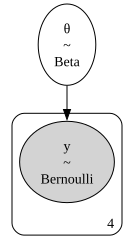

In [7]:
pm.model_to_graphviz(our_first_model)

## 6. Diagnósticos de Convergência MCMC

### 6.1 Gráfico de Traço e Densidade (`az.plot_trace_dist`)
Antes de interpretar qualquer resultado bayesiano gerado via MCMC, devemos verificar se as cadeias convergiram para a distribuição estacionária:
* **Painel Esquerdo (Densidades Marginais por Cadeia):** Exibe as curvas de densidade (KDE) das $4$ cadeias independentes para $\theta$. Como as $4$ curvas se sobrepõem de maneira suave e consistente (com pico próximo a $0.25$–$0.30$ e cauda alongada à direita), há forte concordância entre as cadeias.
* **Painel Direito (*Traceplot* / Série Temporal das Amostras):** Mostra os valores amostrados ao longo das $1000$ iterações. O aspecto de "ruído branco" (semelhante a uma lagarta peluda horizontal, sem tendências de subida/descida e sem trechos horizontais travados) confirma que o amostrador explorou eficientemente o espaço paramétrico.

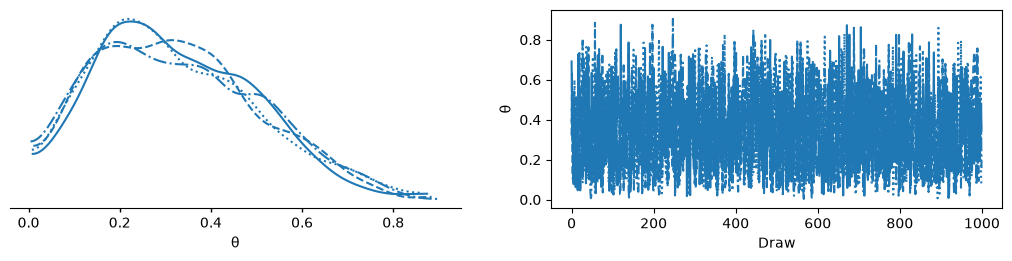

In [8]:
az.plot_trace_dist(idata)

### 6.2 Gráfico de Ranks (`az.plot_rank`)
O **Rank Plot** (proposto por Vehtari et al.) é um diagnóstico moderno e mais sensível que o *traceplot* tradicional:
* Todas as amostras das $4$ cadeias são ordenadas (ranqueadas) em conjunto e depois reagrupadas por cadeia em histogramas.
* **Interpretação do resultado:** Se todas as cadeias estiverem amostrando exatamente da mesma distribuição *a posteriori*, os *ranks* de cada cadeia devem seguir uma **distribuição uniforme** (barras com alturas próximas à linha tracejada horizontal). O gráfico mostra histogramas uniformes nas $4$ cadeias, atestando excelente mistura (*mixing*) e ausência de problemas de convergência.

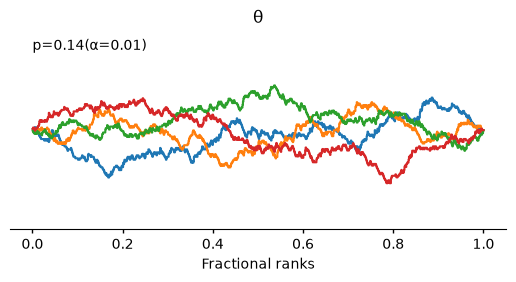

In [9]:
az.plot_rank(idata)

## 7. Resumo Numérico da Distribuição *a Posteriori* (`az.summary`)
Extraímos as estatísticas descritivas da distribuição *a posteriori* de $\theta$:

| Métrica | Valor Obtido | Valor Analítico Exato $\text{Beta}(2, 4)$ | Interpretação Estatística |
| :--- | :---: | :---: | :--- |
| **`mean`** | `0.33` | $\frac{\alpha}{\alpha+\beta} = \frac{2}{6} \approx 0.333$ | Média *a posteriori* de $\theta$. Note o efeito de regularização da *prior* $\text{Beta}(1,1)$ (média $0.50$) puxando a frequência amostral bruta ($\frac{1}{4} = 0.25$) para $0.33$, muito próxima do valor real $\theta_{\text{real}} = 0.35$. |
| **`sd`** | `0.18` | $\sqrt{\frac{2 \times 4}{6^2 \times 7}} \approx 0.178$ | Desvio-padrão *a posteriori*. O valor elevado ($18\%$) reflete honestamente a alta incerteza devido ao tamanho amostral pequeno ($N=4$). |
| **`hdi94_lb` / `hdi94_ub`** | `[0.025, 0.64]` | $[0.025, 0.641]$ | **Intervalo de Credibilidade HDI de 94%:** Dada a amostra observada e o modelo, há $94\%$ de probabilidade de que o verdadeiro viés $\theta$ da moeda esteja entre $2.5\%$ e $64\%$. |

In [10]:
az.summary(idata, kind='stats').round(2)

,mean,sd,hdi94_lb,hdi94_ub
θ,0.33,0.18,0.025,0.64


## 8. Visualização da Posterior e Análise de Decisão (Estilo de Kruschke)

### 8.1 Distribuição *a Posteriori* com Limites do HDI de 94%
Plotamos a densidade *a posteriori* de $\theta$ anotando as linhas verticais e os valores exatos do limite inferior (`0.02`) e superior (`0.64`) do **HDI de 94%**, além da estimativa pontual (`0.33 mean`):
* **Assimetria da distribuição:** Como observamos apenas $1$ cara em $4$ jogadas e $\theta$ é limitado inferiormente em $0$, a distribuição $\text{Beta}(2, 4)$ apresenta assimetria positiva (cauda longa à direita).
* **Diferença para a estatística frequentista:** Na inferência bayesiana, podemos afirmar diretamente que *"a probabilidade de $\theta$ pertencer ao intervalo $[0.02, 0.64]$ é de $94\%$"*.

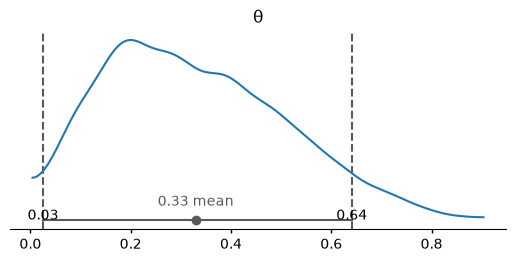

In [11]:
hdi_ds = az.hdi(idata, prob=0.94).dataset
pc = az.plot_dist(idata, ci_kind="hdi", ci_prob=0.94)
az.add_lines(pc, values=hdi_ds, ref_dim="ci_bound")
# Escreve os valores do limite inferior e superior no gráfico
for bound in ("lower", "upper"):
    b_ds = hdi_ds.sel(ci_bound=bound)
    pc.map(
        viz.annotate_xy,
        f"hdi_{bound}_text",
        data=b_ds,
        x=b_ds,
        y=0.05,
        text=lambda val: f"{val:.2f}",
        ignore_aes="all",
    )

### 8.2 Região de Equivalência Prática — ROPE (*Region of Practical Equivalence*)
Na prática, raramente nos importa se uma moeda tem $\theta = 0.50000$ exato; qualquer valor suficientemente próximo de $0.5$, por exemplo no intervalo $\text{ROPE} = [0.45, 0.55]$, pode ser considerado **praticamente equivalente a uma moeda justa**.

Aplicando a **Regra de Decisão HDI + ROPE de Kruschke**:
1. **Rejeitar a hipótese de moeda justa:** Se $100\%$ do HDI de 94% estiver **fora** do ROPE.
2. **Aceitar a hipótese de moeda justa:** Se $100\%$ do HDI de 94% estiver **dentro** do ROPE.
3. **Abster-se (inconclusivo):** Se o HDI e o ROPE se sobrepuserem parcialmente.

* **Interpretação do resultado (`14.9% in ROPE`):** Como apenas cerca de $14.9\%$ do intervalo de credibilidade cai dentro da faixa $[0.45, 0.55]$ e o HDI ($[0.02, 0.64]$) atravessa completamente o ROPE, o resultado é **inconclusivo**: com apenas $4$ lançamentos, não há evidência suficiente nem para afirmar que a moeda é viciada, nem para confirmar que é justa.

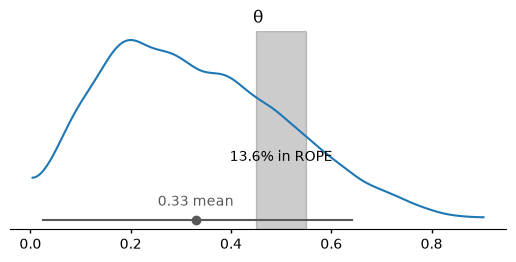

In [12]:
az.plot_dist(idata, var_names='θ', rope=[0.45, 0.55])

### 8.3 Comparação com Valor de Referência Pontual (`ref_val = 0.5`)
Adicionamos uma linha vertical em $\theta = 0.5$ (valor teórico de uma moeda perfeitamente honesta) e calculamos a massa de probabilidade *a posteriori* abaixo e acima desse limiar:
* **$P(\theta < 0.5 \mid y) = 81.7\%$:** Há $81.7\%$ de probabilidade *a posteriori* de que a moeda seja enviesada a favor de "coroa" ($\theta < 0.5$).
* **$P(\theta > 0.5 \mid y) = 18.3\%$:** Há $18.3\%$ de probabilidade *a posteriori* de que a moeda seja enviesada a favor de "cara" ($\theta > 0.5$).

**Conclusão Geral:** O modelo bayesiano capturou corretamente a direção do viés real ($\theta_{\text{real}} = 0.35 < 0.5$), atribuindo mais de $4\times$ mais probabilidade para $\theta < 0.5$ do que para $\theta > 0.5$ ($81.7\%$ vs $18.3\%$), ao mesmo tempo em que evitou conclusões precipitadas graças à largura do HDI de 94% ($[0.02, 0.64]$).

81.7% < 0.5 < 18.3%


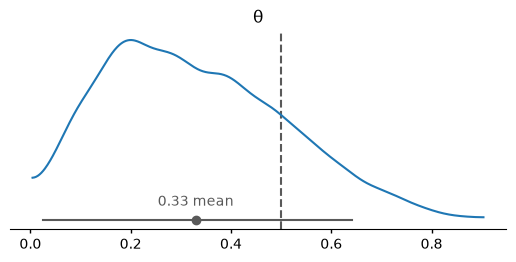

In [13]:
pc = az.plot_dist(idata)
az.add_lines(pc, values=0.5)
p_menor = float((idata.posterior['θ'] < 0.5).mean())
print(f'{p_menor:.1%} < 0.5 < {1-p_menor:.1%}')